# Dar_023 — Terrain-source support and environmental comparisons

Environmental EDA supporting Moon base-location comparison with terrain. Existing data only; no mission/equipment policy is adopted.

## Questions

- Q33: How much of each regional grid has finite image-supported SDEM slope/elevation/roughness?
- Q34: How do paired 30 m SDEM and 40 m LOLA slopes/elevations differ?
- Q35: Do illustrative slope classifications change with terrain source?
- Q36: Does the joint light/Earth-visibility subset change that source comparison?
- Q37: What SDEM support and slope differences exist in the 21 component examples?
- Q38: How does image-supported local elevation SD vary across solar-visibility bands?

## Input contract, comparisons and limitations

Reuse the completed 05 source run; do not extract or regenerate terrain. Sample at the same accepted 60 m analysis centers, using containing native pixels and source CRS/scales. The SDEM source uses the upstream 0.99 image-support definition and an 11-cell/30 m local-SD window. Compare three explicitly named support cohorts. Differences include resolution, processing and support; neither DEM is independent ground truth. The 5/10/15 degree cuts are diagnostic only.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0]=[str(ROOT / "darrel stuff/EDA/shared"), str(ROOT / "darrel stuff/EDA/Moon/Stage3_Requirements"),str(ROOT)]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from environment_workflow import LocalRun as Run,latest_completed_run
from decision_eda import accepted_input
from site_comparison import cohort_rows
from environmental_selection_eda import candidate_thermal_profiles
from terrain_followup_eda import (SDEM_VARIABLES,terrain_source_statistics,slope_classification_comparison,
    candidate_source_support,illumination_roughness,sample_sdem_products,documented_nominal_bin_size,
    nominal_box_overlap,conditional_rank_relationship)
import terrain_followup_eda as methods
REGION_LIMIT=None  # First execute with 1; None is the complete seven-region scope.
spatial=latest_completed_run(ROOT,'analysis/dar_019_spatial_environment','20261106T175056432784Z_dfd0ab')
candidate=latest_completed_run(ROOT,'analysis/dar_020_candidate_environment','20261106T175311055762Z_b68ce6')
joint=latest_completed_run(ROOT,'analysis/dar_012_joint_environment','20261106T134155791814Z_c6f9ab')
thermal=latest_completed_run(ROOT,'analysis/dar_001_temperature_local_time','20261106T082643415392Z_4e6a0b')
environment=latest_completed_run(ROOT,'analysis/dar_002_temperature_environment','20261106T082929336242Z_623f9f')
sdem=latest_completed_run(ROOT,'lunar_terrain_environment','20261106T180253772848Z_40d3f3')
def regions_in(values):
    regions=sorted(values)
    if REGION_LIMIT is not None:
        if type(REGION_LIMIT) is not int or not 1<=REGION_LIMIT<=len(regions):raise ValueError('Invalid region limit')
        regions=regions[:REGION_LIMIT]
    return regions
def register(run):
    run.input(Path(methods.__file__))
    for name in ['decision_eda.py','moon_p1_analysis.py','site_comparison.py','environmental_selection_eda.py']:
        run.input(ROOT/'darrel stuff/EDA'/name)
def savefig(run,fig,name):
    fig.savefig(run.path(name+'.png'),dpi=120,bbox_inches='tight');display(fig);plt.close(fig)
def publish(run,record):
    run.path('findings.json').write_text(json.dumps(record,indent=2,default=str),encoding='utf-8');display(record)

Accepted local analysis/dar_019_spatial_environment run: 20261106T175056432784Z_dfd0ab
Accepted local analysis/dar_020_candidate_environment run: 20261106T175311055762Z_b68ce6
Accepted local analysis/dar_012_joint_environment run: 20261106T134155791814Z_c6f9ab
Accepted local analysis/dar_001_temperature_local_time run: 20261106T082643415392Z_4e6a0b
Accepted local analysis/dar_002_temperature_environment run: 20261106T082929336242Z_623f9f
Accepted local lunar_terrain_environment run: 20261106T180253772848Z_40d3f3


## Execute the bounded comparison

Completed source runs are pinned and checked. Raw data and older notebooks remain unchanged. Read per-group counts and missingness before interpreting summaries.

A3CLR22_10_Leibnitz_Beta_Plateau sampled 70756 cells
A3CLR22_11_Malapert_Massif sampled 121801 cells
A3CLR22_12_deGerlache_Kocher_Massif sampled 110889 cells
A3CLR22_2_Haworth sampled 246016 cells
A3CLR22_3_Faustini_Rim_A sampled 110556 cells
A3CLR22_4_deGerlache_Rim_2 sampled 110224 cells
A3CLR22_5_Connecting_Ridge_Extension sampled 110224 cells


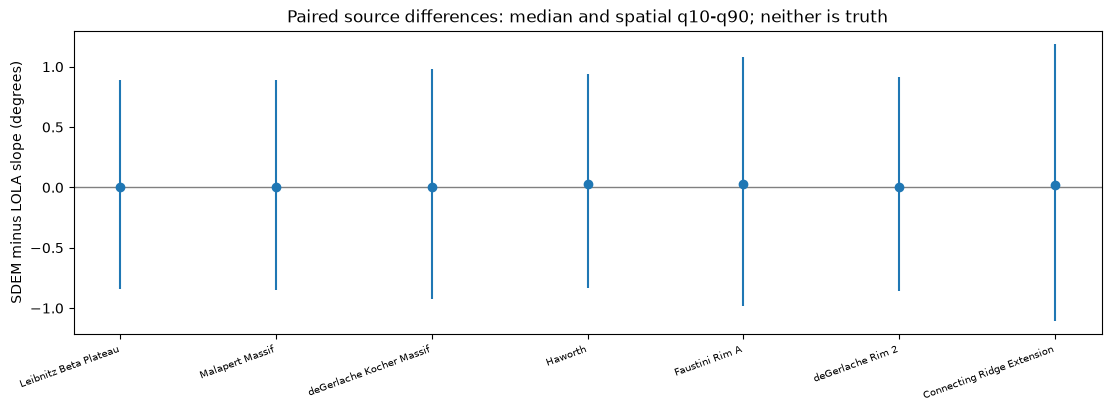

,region,analysis_cells,finite_lola_slope_cells,finite_sdem_slope_cells,finite_sdem_local_std_cells,complete_sdem_features_cells
0,A3CLR22_10_Leibnitz_Beta_Plateau,70756,70756,62789,48881,48881
1,A3CLR22_11_Malapert_Massif,121801,121801,114528,98087,98087
2,A3CLR22_12_deGerlache_Kocher_Massif,110889,110889,104369,93117,93117
3,A3CLR22_2_Haworth,246016,246016,204766,129510,129510
4,A3CLR22_3_Faustini_Rim_A,110556,110556,72882,45963,45963
5,A3CLR22_4_deGerlache_Rim_2,110224,110224,96585,75494,75494
6,A3CLR22_5_Connecting_Ridge_Extension,110224,110224,101961,84053,84053


,candidate_id,analysis_cells,finite_sdem_slope_cells,unknown_sdem_slope_cells,complete_sdem_feature_cells,sdem_slope_median_deg,sdem_slope_q90_deg,sdem_slope_above_diagnostic_limit_cells,sdem_slope_above_fraction_of_finite,zero_lola_spot_cells,diagnostic_limit_deg,interpretation,region
0,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,157,151,6,95,4.461726,6.912300,1,0.006623,6,10.0,"alternative-source diagnostic, not operational...",A3CLR22_10_Leibnitz_Beta_Plateau
1,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,59,54,5,27,5.901962,9.014588,1,0.018519,1,10.0,"alternative-source diagnostic, not operational...",A3CLR22_10_Leibnitz_Beta_Plateau
2,A3CLR22_10_Leibnitz_Beta_Plateau:diagnostic_co...,42,41,1,30,6.278141,8.324826,0,0.000000,0,10.0,"alternative-source diagnostic, not operational...",A3CLR22_10_Leibnitz_Beta_Plateau
3,A3CLR22_11_Malapert_Massif:diagnostic_componen...,174,133,41,2,5.155419,9.086912,6,0.045113,0,10.0,"alternative-source diagnostic, not operational...",A3CLR22_11_Malapert_Massif
4,A3CLR22_11_Malapert_Massif:diagnostic_componen...,164,151,13,74,7.314586,9.564489,8,0.052980,1,10.0,"alternative-source diagnostic, not operational...",A3CLR22_11_Malapert_Massif
5,A3CLR22_11_Malapert_Massif:diagnostic_componen...,96,90,6,61,6.000251,8.472521,1,0.011111,0,10.0,"alternative-source diagnostic, not operational...",A3CLR22_11_Malapert_Massif
6,A3CLR22_12_deGerlache_Kocher_Massif:diagnostic...,35,35,0,33,6.409988,8.528241,1,0.028571,6,10.0,"alternative-source diagnostic, not operational...",A3CLR22_12_deGerlache_Kocher_Massif
7,A3CLR22_12_deGerlache_Kocher_Massif:diagnostic...,24,24,0,13,4.827045,8.533800,0,0.000000,1,10.0,"alternative-source diagnostic, not operational...",A3CLR22_12_deGerlache_Kocher_Massif
8,A3CLR22_12_deGerlache_Kocher_Massif:diagnostic...,22,22,0,13,3.753576,6.625521,0,0.000000,0,10.0,"alternative-source diagnostic, not operational...",A3CLR22_12_deGerlache_Kocher_Massif
9,A3CLR22_2_Haworth:diagnostic_component_00014,75,59,16,22,5.957635,8.102654,0,0.000000,0,10.0,"alternative-source diagnostic, not operational...",A3CLR22_2_Haworth


{'questions': ['Q33', 'Q34', 'Q35', 'Q36', 'Q37', 'Q38'],
 'regions': 7,
 'sampled_analysis_cells': 880466,
 'candidate_examples': 21,
 'candidates_with_some_sdem_slope_missing': 18,
 'candidates_with_sdem_slope_above_diagnostic_10deg': 11,
 'paired_statistics': [{'region': 'A3CLR22_10_Leibnitz_Beta_Plateau',
   'pair_count': 62789,
   'difference_median': 0.0040683746337890625,
   'spearman_rho': 0.9922780149607179},
  {'region': 'A3CLR22_11_Malapert_Massif',
   'pair_count': 114528,
   'difference_median': 0.0032320022583007812,
   'spearman_rho': 0.9930560588715759},
  {'region': 'A3CLR22_12_deGerlache_Kocher_Massif',
   'pair_count': 104369,
   'difference_median': 0.0043544769287109375,
   'spearman_rho': 0.9875524190459717},
  {'region': 'A3CLR22_2_Haworth',
   'pair_count': 204766,
   'difference_median': 0.02912759780883878,
   'spearman_rho': 0.9879193898709749},
  {'region': 'A3CLR22_3_Faustini_Rim_A',
   'pair_count': 72882,
   'difference_median': 0.025351524353028232,
   '

In [2]:
config={'region_limit':REGION_LIMIT,'sdem_run':str(sdem.relative_to(ROOT)),'spatial_run':str(spatial.relative_to(ROOT)),
    'sample_spacing_m':60,'sdem_spacing_m':30,'lola_spacing_m':40,'diagnostic_slope_cuts_deg':[5,10,15],
    'reference_truth':None,'operational_policy_adopted':False}
with Run(ROOT,'analysis/dar_023_terrain_source_sensitivity',config,
    'Moon/Terrain_And_Soil/Dar_023_terrain_environment_source_sensitivity.ipynb') as run:
    register(run)
    footprints=json.loads(accepted_input(run,thermal,'region_footprints.json').read_text())
    examples=pd.read_csv(accepted_input(run,spatial,'diagnostic_candidate_manifest.csv'))
    source=json.loads((sdem/'provenance.json').read_text());run.input(sdem/'provenance.json')
    if source['config']['minimum_image_support_fraction']!=.99:raise ValueError('Unexpected source support definition')
    regions=regions_in(footprints);statistics=[];classes=[];support=[];roughness=[];coverage=[];sample_cells=[]
    columns=['region','row','col','x_m','y_m','solar_visibility','earth_visibility','slope_deg','elevation_m','spot_count','candidate_id']
    for region in regions:
        cells=pd.read_csv(accepted_input(run,spatial,'grids/'+region+'.csv.gz'),usecols=columns,dtype={'candidate_id':'string'})
        paired=sample_sdem_products(run,sdem,region,cells,footprints[region]['bounds_m'])
        for result,collection in [(terrain_source_statistics(paired),statistics),
            (slope_classification_comparison(paired),classes),(illumination_roughness(paired),roughness)]:
            result['region']=region;collection.append(result)
        ids=examples.loc[examples.region.eq(region),'candidate_id'].tolist()
        result=candidate_source_support(paired,ids);result['region']=region;support.append(result)
        coverage.append({'region':region,'analysis_cells':len(paired),
            'finite_lola_slope_cells':int(paired.slope_deg.notna().sum()),
            'finite_sdem_slope_cells':int(paired.sdem_slope_deg.notna().sum()),
            'finite_sdem_local_std_cells':int(paired.sdem_local_std_m.notna().sum()),
            'complete_sdem_features_cells':int(np.isfinite(paired[list(SDEM_VARIABLES)]).all(axis=1).sum())})
        sample_cells.append(paired.loc[paired.candidate_id.notna()])
        print(region,'sampled',len(paired),'cells',flush=True)
    statistics=pd.concat(statistics,ignore_index=True);classes=pd.concat(classes,ignore_index=True)
    support=pd.concat(support,ignore_index=True);coverage=pd.DataFrame(coverage)
    statistics.to_csv(run.path('terrain_source_pair_statistics.csv'),index=False)
    classes.to_csv(run.path('slope_source_classification.csv'),index=False)
    support.to_csv(run.path('candidate_sdem_support.csv'),index=False)
    coverage.to_csv(run.path('sdem_sampling_coverage.csv'),index=False)
    pd.concat(roughness,ignore_index=True).to_csv(run.path('solar_band_sdem_roughness.csv'),index=False)
    pd.concat(sample_cells,ignore_index=True).to_csv(run.path('illustrative_candidate_source_cells.csv.gz'),index=False,compression={'method':'gzip','mtime':0})
    p=statistics.loc[statistics.variable.eq('slope')&statistics.cohort.eq('finite_slope_pair')].set_index('region').reindex(regions)
    fig,ax=plt.subplots(figsize=(11,4),layout='constrained');ax.errorbar(range(len(p)),p.difference_median,
        yerr=np.vstack([p.difference_median-p.difference_q10,p.difference_q90-p.difference_median]),fmt='o')
    ax.axhline(0,color='grey',lw=1);ax.set_xticks(range(len(p)),[x.split('_',2)[-1].replace('_',' ') for x in regions],rotation=20,ha='right',fontsize=7)
    ax.set(ylabel='SDEM minus LOLA slope (degrees)',title='Paired source differences: median and spatial q10-q90; neither is truth')
    savefig(run,fig,'terrain_source_slope_differences');display(coverage);display(support)
    publish(run,{'questions':['Q%02d'%i for i in range(33,39)],'regions':len(regions),
        'sampled_analysis_cells':int(coverage.analysis_cells.sum()),
        'candidate_examples':len(support),'candidates_with_some_sdem_slope_missing':int(support.unknown_sdem_slope_cells.gt(0).sum()),
        'candidates_with_sdem_slope_above_diagnostic_10deg':int(support.sdem_slope_above_diagnostic_limit_cells.gt(0).sum()),
        'paired_statistics':p.reset_index()[['region','pair_count','difference_median','spearman_rho']].to_dict('records'),
        'limits':['30 m processed SDEM and 40 m LOLA have different source support and processing',
        'Image-supported derivative gaps remain unknown; no reconstruction performed','Source differences are not accuracy estimates or operational failures']})
OUT=run.directory

## Findings and interpretation

The executed tables, plots and `findings.json` above contain the measured results. Undefined or absent groups are findings, not zero effects. Inspect the declared support/cohort controls rather than selecting whichever result looks most favourable.

## Outputs and next analysis

Generated tables/plots/provenance stay under `darrel stuff/data/processed/analysis/`. See [EDA notes](../../EDA_Notes.md) and [EDA results](../../EDA_Notes.md) for status/findings. Proposed algorithm consumption belongs in the [root overview/proposal](../../../Brief_Overview.md#algorithm-proposal), not a duplicated implementation plan here.